# Practice Problems

Twelve short, self-checking exercises covering Chapters 2-10. Each one has a bit of physics behind it and asks for a single number (or a few).

**How to use this notebook**
1. Run the first code cell - it defines `check(problem, answer)`.
2. For each problem, replace `answer = None` with your own code that computes the answer. **Don't type the number in by hand - compute it!**
3. Run the `check(...)` cell: you'll see ✅ if you're within tolerance, ❌ if not, and ⏳ if you haven't attempted it yet.

Worked solutions are in `practice-solutions.ipynb` - try properly before you peek! (Yes, you *could* read the reference values in the checker cell, but you'd only be cheating yourself.)

| # | Topic | Chapter |
| :-: | :--- | :-: |
| 1 | Wien's law in frequency form | 3 (Newton-Raphson) |
| 2 | How deep does a floating ball sink? | 2 (bisection) |
| 3 | A Gaussian moment integral | 4 (Simpson + substitution) |
| 4 | Gravity on the Moon from video data | 4 (finite differences) |
| 5 | Falling with air resistance | 5 (RK4 / events) |
| 6 | A pendulum released at 90° | 5 (Verlet / RK4) |
| 7 | Mesh currents in a circuit | 6 (Gaussian elimination) |
| 8 | The lowest mode of a chain of masses | 6 (inverse iteration) |
| 9 | Cooling of a rod | 7 (FTCS) |
| 10 | Find the hidden tone | 8 (FFT) |
| 11 | RC discharge: fitting a lifetime | 9 (curve fitting) |
| 12 | The Steinmetz solid | 10 (Monte Carlo) |

In [1]:
# Run this cell first.
import numpy as np
import matplotlib.pyplot as plt

_REFERENCE = {   # problem: (reference value, tolerance, 'rel' or 'abs')
    1: (2.82143937212, 1e-8, 'rel'),
    2: (1.13413784570, 1e-6, 'rel'),
    3: (0.44311346273, 1e-6, 'rel'),
    4: (-1.62, 1e-3, 'rel'),
    5: (5.30987470485, 1e-5, 'rel'),
    6: (1.18034059902, 1e-4, 'rel'),
    7: ([0.53164557, 0.13924051, 0.01265823], 1e-6, 'abs'),
    8: (0.51763809021, 1e-6, 'rel'),
    9: (0.37270783885, 2e-3, 'abs'),
    10: (37.0, 0.5, 'abs'),
    11: (2.47, 0.05, 'abs'),
    12: (4.68629150102, 0.05, 'abs'),
}

_RESULTS = {}    # problem -> True (correct), False (wrong) or None (not attempted)

def check(problem, answer):
    """Print a verdict for this problem, record it in _RESULTS and return it."""
    if answer is None:
        print(f'⏳ Problem {problem}: not attempted yet')
        _RESULTS[problem] = None
        return None
    ref, tol, kind = _REFERENCE[problem]
    ref, ans = np.asarray(ref, float), np.asarray(answer, float)
    if ans.shape != ref.shape:
        print(f'❌ Problem {problem}: expected an answer of shape {ref.shape}, got {ans.shape}')
        _RESULTS[problem] = False
        return False
    err = np.max(np.abs(ans - ref)) if kind == 'abs' else np.max(np.abs(ans/ref - 1))
    if err <= tol:
        print(f'✅ Problem {problem}: correct! ({kind} error {err:.1e})')
        _RESULTS[problem] = True
    else:
        print(f'❌ Problem {problem}: not quite - your answer is {np.round(ans, 6)}. Keep going!')
        _RESULTS[problem] = False
    return _RESULTS[problem]

def progress():
    """Summarise every check() you've run so far."""
    done = sum(v is True for v in _RESULTS.values())
    wrong = [p for p, v in sorted(_RESULTS.items()) if v is False]
    todo = [p for p in _REFERENCE if _RESULTS.get(p) is None]
    print(f'{done}/{len(_REFERENCE)} correct' + (f', still wrong: {wrong}' if wrong else '')
          + (f', not attempted: {todo}' if todo else ''))

---
## Problem 1 - Wien's law in frequency form *(Chapter 3)*
If you maximise Planck's law per unit **frequency** instead of per unit wavelength (as in the Optics applications notebook), the peak occurs at $x = h\nu/k_BT$ satisfying

$$3\left(1 - e^{-x}\right) = x, \qquad x > 0.$$

Use **Newton-Raphson** (write it yourself!) starting from $x_0=3$ to find $x$ to at least 10 significant figures.

In [2]:
answer = None   # replace with your Newton-Raphson code
check(1, answer)

⏳ Problem 1: not attempted yet


## Problem 2 - How deep does a floating ball sink? *(Chapter 2)*
A solid sphere of radius $R$ and relative density $s=0.6$ floats in water. By Archimedes, the submerged depth $h$ (in units of $R$) satisfies

$$h^3 - 3h^2 + 4s = 0, \qquad 0 < h < 2.$$

Use **bisection** on $[0, 2]$ to find $h$ to $10^{-10}$.

In [3]:
answer = None   # replace with your bisection code
check(2, answer)

⏳ Problem 2: not attempted yet


## Problem 3 - A Gaussian moment integral *(Chapter 4)*
The mean kinetic energy of a particle in a harmonic trap involves

$$I = \int_0^\infty x^2e^{-x^2}\,dx.$$

Map the infinite range onto $[0,1)$ with $x = t/(1-t)$ and evaluate the integral with **your own composite Simpson's rule** using 1000 strips. (Hint: the transformed integrand at $t=1$ is $0$ - but you'll need to treat that point carefully to avoid dividing by zero.)

In [4]:
answer = None   # replace with your Simpson's rule code
check(3, answer)

⏳ Problem 3: not attempted yet


## Problem 4 - Gravity on the Moon from video data *(Chapter 4)*
An astronaut throws a rock upwards and a video tracks its height every 0.1 s (data below). Estimate the gravitational acceleration from the data using the **central second-difference** formula $\frac{y_{i+1}-2y_i+y_{i-1}}{\Delta t^2}$ at every interior point, then average. (Your answer is negative because it points down.)

In [5]:
t_data = np.linspace(0, 3, 31)
y_data = 1.5 + 4*t_data - 0.81*t_data**2          # height in metres (no noise - lucky astronaut)

In [6]:
answer = None   # replace with your finite-difference code
check(4, answer)

⏳ Problem 4: not attempted yet


## Problem 5 - Falling with air resistance *(Chapter 5)*
A small object is dropped from rest from a height of 100 m. With linear drag its velocity obeys $\dot v = g - kv$ (taking down as positive) with $g = 9.81$ m/s² and $k=0.2$ s⁻¹. How long does it take to hit the ground?

Solve the system $\dot y = v,\ \dot v = g - kv$ with **RK4** (your own, $h=10^{-3}$ s) and find the landing time by linear interpolation between the last two steps - or use `solve_ivp` with an event. *(Bonus: there is an analytic solution - find the time with Newton-Raphson as a check.)*

In [7]:
answer = None   # replace with your RK4 code
check(5, answer)

⏳ Problem 5: not attempted yet


## Problem 6 - A pendulum released at 90° *(Chapter 5)*
A pendulum obeys $\ddot\theta = -\sin\theta$ (units with $g/L=1$, so the small-angle period is $T_0 = 2\pi$). It is released from rest at $\theta_0=90°$. Find the ratio $T/T_0$ by simulation: integrate with **velocity Verlet** ($h = 10^{-4}$) until $\theta$ first crosses zero, which happens at $T/4$.

In [8]:
answer = None   # replace with your Verlet code
check(6, answer)

⏳ Problem 6: not attempted yet


## Problem 7 - Mesh currents in a circuit *(Chapter 6)*
Kirchhoff's voltage law for a three-loop circuit gives (currents in A, resistances in Ω, voltages in V)

$$\begin{pmatrix}10 & -2 & -3\\ -2 & 8 & -4\\ -3 & -4 & 12\end{pmatrix}\begin{pmatrix}I_1\\I_2\\I_3\end{pmatrix} = \begin{pmatrix}5\\0\\-2\end{pmatrix}.$$

Solve it with **your own Gaussian elimination with partial pivoting**, and give the answer as an array `[I1, I2, I3]`.

In [9]:
answer = None   # replace with your Gaussian elimination code
check(7, answer)

⏳ Problem 7: not attempted yet


## Problem 8 - The lowest mode of a chain of masses *(Chapter 6)*
Five equal masses $m=1$ are joined in a line by six identical springs $k=1$, with the ends fixed to walls. The squared normal-mode frequencies are the eigenvalues of the $5\times5$ tridiagonal matrix with $2$ on the diagonal and $-1$ on the off-diagonals. Find the **lowest angular frequency** $\omega$ using **inverse iteration** (power iteration on $K^{-1}$ - use a linear solve, not `inv`).

In [10]:
answer = None   # replace with your inverse-iteration code
check(8, answer)

⏳ Problem 8: not attempted yet


## Problem 9 - Cooling of a rod *(Chapter 7)*
A rod of length 1 with ends held at zero obeys $u_t = u_{xx}$, with initial temperature $u(x,0)=\sin(\pi x)$. Use **FTCS** with 51 grid points and $r = \Delta t/\Delta x^2 = 0.25$ to find the temperature at the centre at $t=0.1$.

In [11]:
answer = None   # replace with your FTCS code
check(9, answer)

⏳ Problem 9: not attempted yet


## Problem 10 - Find the hidden tone *(Chapter 8)*
The signal below contains two pure tones buried in noise that is much louder than either of them. Use the **FFT** to find the frequency (in Hz) of the **strongest** tone.

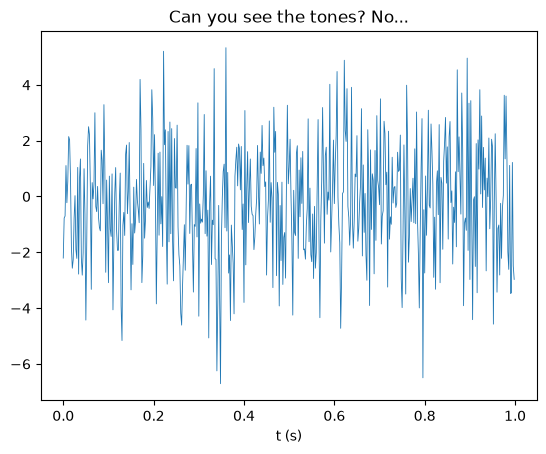

In [12]:
rng = np.random.default_rng(10)
fs = 500
t_sig = np.arange(0, 4, 1/fs)
signal = 0.7*np.sin(2*np.pi*37*t_sig) + 0.4*np.sin(2*np.pi*91*t_sig) + 2*rng.normal(size=t_sig.size)
plt.plot(t_sig[:500], signal[:500], lw=0.6); plt.xlabel('t (s)'); plt.title('Can you see the tones? No...'); plt.show()

In [13]:
answer = None   # replace with your FFT code
check(10, answer)

⏳ Problem 10: not attempted yet


## Problem 11 - RC discharge: fitting a lifetime *(Chapter 9)*
A capacitor discharges through a resistor, $V(t) = V_0e^{-t/\tau}$. The (noisy) voltmeter readings are below; each has an uncertainty of 0.05 V. Fit for $\tau$ using `scipy.optimize.curve_fit` and also print its uncertainty and the reduced $\chi^2$.

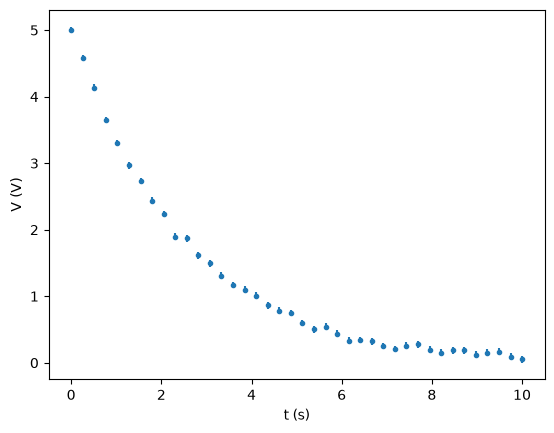

In [14]:
rng = np.random.default_rng(11)
t_rc = np.linspace(0, 10, 40)
V_rc = 5*np.exp(-t_rc/2.5) + rng.normal(0, 0.05, t_rc.size)
plt.errorbar(t_rc, V_rc, 0.05, fmt='o', ms=3); plt.xlabel('t (s)'); plt.ylabel('V (V)'); plt.show()

In [15]:
answer = None   # replace with your fitting code
check(11, answer)

⏳ Problem 11: not attempted yet


## Problem 12 - The Steinmetz solid *(Chapter 10)*
Three cylinders of radius 1 along the $x$, $y$ and $z$ axes intersect in a curved solid (the *tricylinder Steinmetz solid*): the points with $x^2+y^2\le1$, $y^2+z^2\le1$ **and** $x^2+z^2\le1$. Estimate its volume with **Monte Carlo** by throwing at least $10^6$ random points into the cube $[-1,1]^3$. Print your error estimate too.

In [16]:
answer = None   # replace with your Monte Carlo code
check(12, answer)

⏳ Problem 12: not attempted yet


## How did you do?
Run the cell below for a summary of every `check()` you've run.

In [17]:
progress()

0/12 correct, not attempted: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


<details>
<summary>Secret problem</summary>

## Problem 13 - Secret problem *(Chapter 3)*
In single-slit diffraction (Applications III, section A3.2), the intensity is $I\propto\left(\frac{\sin\beta}{\beta}\right)^2$. Its secondary maxima are **not** halfway between the zeros: setting $dI/d\beta=0$ gives the transcendental equation

$$\tan\beta = \beta.$$

Find the first secondary maximum: the smallest **positive** root of $\tan\beta = \beta$ other than $\beta=0$. Careful, $\tan$ has poles. Bracket your root between two of them. The checker only accepts an answer correct to 6 decimal places, and it doesn't reveal the answer.
</details>

In [17]:
answer = None   # replace with your root-finding code

# The secret checker compares a fingerprint (hash) of your answer, so it can't give the answer away.
import hashlib
if answer is None:
    print('⏳ Secret problem: not attempted yet')
else:
    assert hashlib.sha256(f'{answer:.6f}'.encode()).hexdigest() == '4219c0dc7bb72c873730efbc908b3305d50a970080039704d04e74dbb202882d', 'Not quite - keep going!'
    print('✅ Secret problem solved. The first side lobe of a slit is at beta = %.6f, not 3*pi/2 = %.6f.' % (answer, 1.5*3.141592653589793))

⏳ Secret problem: not attempted yet


---
### Finished?
Try going further: each problem can be extended. Measure the order of convergence of your Simpson integral in Problem 3, swap Verlet for Euler in Problem 6 and see how wrong it gets, push $r$ above $0.5$ in Problem 9, or replace Problem 12's uniform sampling with something smarter. Then head to the `Applications` folder for bigger projects.